# Disarm (Mercenary)

Disarm is a passive. Every landed melee hit has a **10% chance** to weaken the defender's grip:
their **Weapon Skill** drops for 45 s. From a modified skill of 100, the proc also hits
adjacent enemies attacking the Mercenary, if they fail a resist roll.

Weapon Skill is the fight skill used for **both attack and defence** (`get_fight_skill`), so one
proc moves the melee hit table in the Mercenary's favour in both directions. The defender misses
more, and the Mercenary hits more often and harder.

| | |
|---|---|
| Class | Mercenary |
| Trigger | 10% per landed, undodged primary melee hit (`disarm_on_hit`), only if `skill[SK_DISARM][0] != 0` |
| Target | Defender; at raw skill ≥ 100 also the caster's 4 cross neighbours that are attacking the caster |
| Cost | none |
| Landing roll | primary: none. Splash: $p + \text{rand}(20) > R + \text{rand}(20)$ |
| Duration | 45 s; every new proc replaces the old item and restarts the timer |
| Effect | `skill[SK_WEAPON][1] += −penalty` (Weapon Skill has a floor of 1) |
| Source | `server/src/driver/skill/mercenary.rs::disarm_on_hit`, `apply_disarm`; hit table in `server/src/state/combat.rs::do_attack` |

---

# Formula

With immunity $I$ and caster race multiplier $r$:

$$
p' = \lfloor r\cdot\text{imm}(p, I)\rfloor
\qquad
\text{penalty} = \operatorname{clamp}\!\left(3\left\lfloor p'/2 \right\rfloor,\ 3,\ 150\right)
$$

The melee roll is a d20 against a chance taken from the difference $\Delta$ between attacker and
defender Weapon Skill. Selected rows:

| $\Delta$ | −41 or less | −40 | −30 | −20 | 0 | +20 | +30 | +40 or more |
|---|---|---|---|---|---|---|---|---|
| hit on d20 ≤ | 1 | 2 | 4 | 7 | 12 | 18 | 19 | 19 |
| damage bonus | −16 / −32 / −64 | −8 | −2 | 0 | 0 | +3 | +5 | +20 |

A penalty $D$ on the defender adds $D$ to the Mercenary's $\Delta$ and subtracts $D$ from the
defender's $\Delta$ against **everyone**.

| Quantity | Breakpoint |
|---|---|
| Penalty ceiling | 150 at $p' \ge 100$: skill 96 for a Mercenary at immunity 0 |
| AoE threshold | raw modified skill ≥ 100 (immunity and race are not applied to this check) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 45
PROC = 0.10
AOE_MIN = 100

# Model

In [2]:
def disarm_power(p, immun=0, race="Mercenary"):
    return mm.spell_power(p, immun, race)


def disarm_penalty(p, immun=0, race="Mercenary"):
    return mm.clamp(mm.idiv(disarm_power(p, immun, race), 2) * 3, 3, 150)


def hit_chances(p, merc_ws=100, enemy_ws=100, immun=0):
    """(Mercenary hit chance, enemy hit chance) once the enemy is disarmed."""
    enemy = np.maximum(1, enemy_ws - disarm_penalty(p, immun))
    return mm.p_melee_hit(merc_ws - enemy), mm.p_melee_hit(enemy - merc_ws)


def p_splash(p, resist, pen_pct=0):
    return np.where(np.asarray(p) >= AOE_MIN, mm.p_opposed_d20(p, mm.effective_resist(resist, pen_pct)), 0.0)


def p_disarmed_by(t, landed_per_s):
    """P(at least one proc within t seconds) at a steady rate of landed hits."""
    return 1 - (1 - PROC) ** np.floor(np.asarray(t) * landed_per_s)

# Validation

`disarm_penalises_weapon_skill_for_45_seconds` passes raw power 40 / 1 / 500 with a race-neutral
caster and immunity 0, and expects penalties of 60 / 3 / 150 and `active == TICKS*45`.

In [3]:
assert disarm_penalty(40, race="Other") == 60
assert disarm_penalty(1, race="Other") == 3
assert disarm_penalty(500, race="Other") == 150
assert mm.TICKS * DURATION_S == 1620

assert disarm_penalty(95) == 147 and disarm_penalty(96) == 150    # Mercenary: p' 99 -> 147, 100 -> 150
assert mm.melee_hit_table(0) == (12, 0) and mm.melee_hit_table(40) == (19, 20)
assert mm.melee_hit_table(-30) == (4, -2) and mm.melee_hit_table(-41) == (1, -16)
print("Disarm model OK")

Disarm model OK


# Plots

skill at which the penalty reaches 150, by immunity: {0: 96, 25: 108, 50: 121, 75: 133, 100: 146}


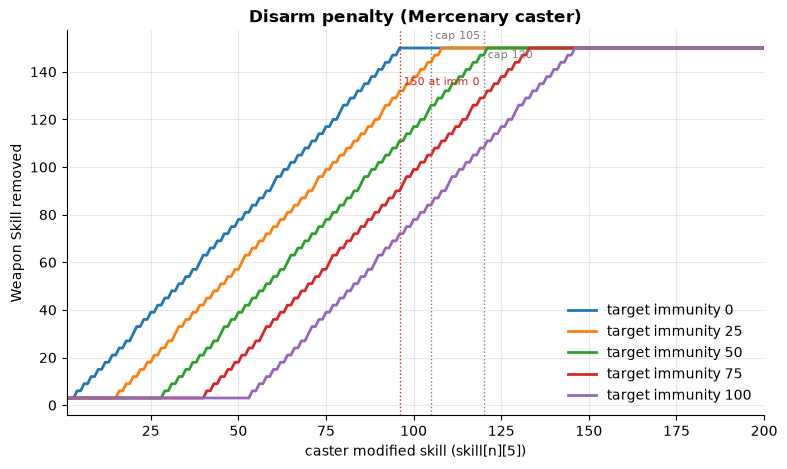

In [4]:
fig, ax = plt.subplots()
sat = []
for immun in mm.IMMUNITY_SWEEP:
    v = disarm_penalty(P, immun)
    ax.plot(P, v, label=f"target immunity {immun}")
    sat.append(int(P[np.argmax(v >= 150)]))
mm.skill_axis(ax, "Weapon Skill removed", "Disarm penalty (Mercenary caster)")
mm.mark_caps(ax, extra=[(sat[0], "150 at imm 0")])
ax.legend(loc="lower right")
print("skill at which the penalty reaches 150, by immunity:", dict(zip(mm.IMMUNITY_SWEEP, sat)))

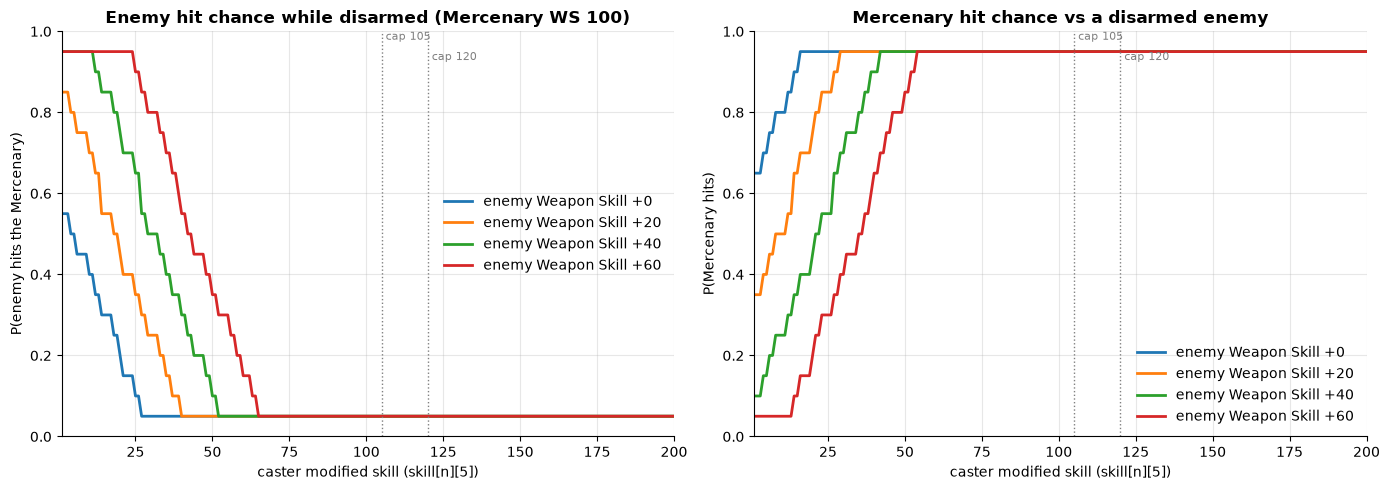

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
advantages = (0, 20, 40, 60)

ax = axes[0]
for adv in advantages:
    _, enemy = hit_chances(P, 100, 100 + adv)
    ax.plot(P, enemy, label=f"enemy Weapon Skill +{adv}")
mm.skill_axis(ax, "P(enemy hits the Mercenary)", "Enemy hit chance while disarmed (Mercenary WS 100)")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for adv in advantages:
    merc, _ = hit_chances(P, 100, 100 + adv)
    ax.plot(P, merc, label=f"enemy Weapon Skill +{adv}")
mm.skill_axis(ax, "P(Mercenary hits)", "Mercenary hit chance vs a disarmed enemy")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

Without Disarm, an evenly matched pair hits each other 60% of the time. A skill-20 Disarm
(penalty 30) already drops the enemy to 20% and lifts the Mercenary to 95%. From skill ~50 the
penalty (78) pins both ends of the table against an even opponent: the enemy hits on a natural
1 only, and the Mercenary gets 95% and +20 damage per hit.

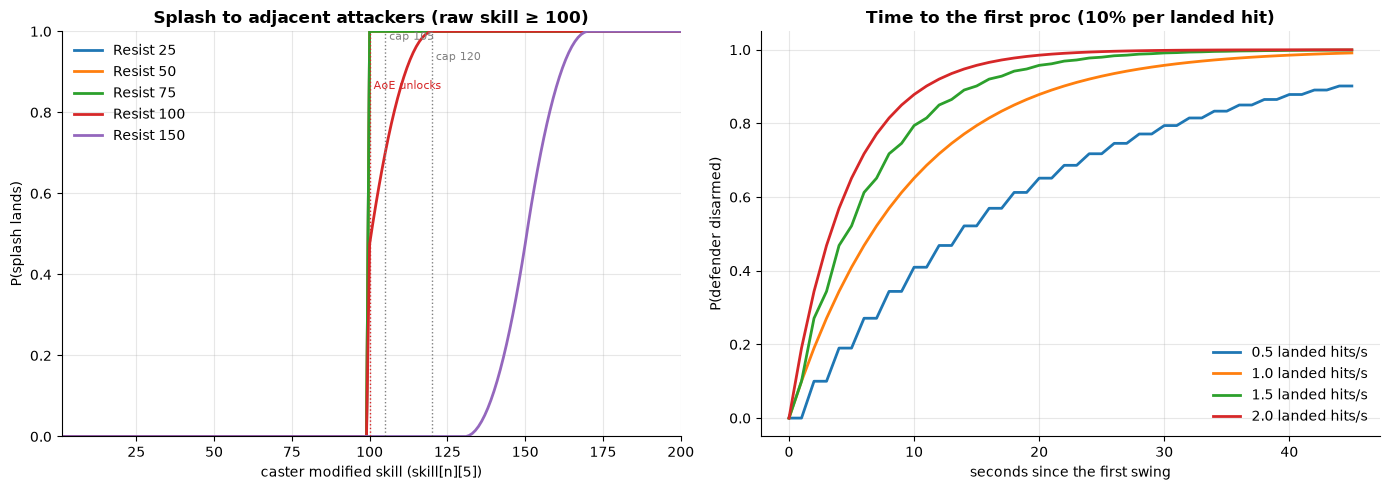

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for resist in mm.RESIST_SWEEP:
    ax.plot(P, p_splash(P, resist), label=f"Resist {resist}")
mm.skill_axis(ax, "P(splash lands)", "Splash to adjacent attackers (raw skill ≥ 100)")
ax.set_ylim(0, 1)
mm.mark_caps(ax, extra=[(AOE_MIN, "AoE unlocks")])
ax.legend()

ax = axes[1]
t = np.arange(0, 46)
for landed in (0.5, 1.0, 1.5, 2.0):
    ax.plot(t, p_disarmed_by(t, landed), label=f"{landed} landed hits/s")
ax.set_xlabel("seconds since the first swing")
ax.set_ylabel("P(defender disarmed)")
ax.set_title("Time to the first proc (10% per landed hit)")
ax.legend()
plt.tight_layout()

# Observations

- **One of the strongest passives in the game, and it saturates early.** The penalty reaches its
  150 ceiling at skill 96 for a Mercenary at immunity 0, below both raise caps. Against an
  evenly matched opponent the effect stops growing much earlier, around skill 50 (penalty 78).
  There the defender only hits on a natural 1 (5%) and the Mercenary hits 95% of the time with
  +20 damage. Against an enemy with +60 Weapon Skill, a skill-105 Disarm still turns 95/5
  (enemy/Mercenary hit chance) into 5/95.
- **Uptime is close to 100% after the first proc.** Each landed hit re-procs at 10% and resets the
  45 s timer. At 1.2 landed hits per second (about 2 swings/s at 60% to hit), the first proc
  comes after about 8 s on average. Once applied, the chance of no new proc in 45 s is 0.3%.
- **It helps everyone attacking the target.** The penalty lowers the defender's Weapon Skill
  itself, so allies hitting the same enemy, and anyone the enemy attacks, also benefit.
- **The splash is gated on raw skill, not power.** The `power < 100` check uses the raw modified
  skill, while the penalty uses $p'$. Immunity therefore never disables the splash, but it weakens
  the penalty every splash target receives. Splash targets roll the opposed d20 with raw skill: at
  skill 100 the splash lands 47.5% of the time on Resist 100 and never on Resist 120 or more.
- **Balance suggestion.** Make the penalty scale more slowly (for example $p'/2$ instead of
  $3p'/2$), or cap it near 40. A 40-point penalty already gives 95% / +20 damage against an
  equal opponent and cuts their hit chance to 10%.